# Мои домашние работы по Теории Вероятности

## Библиотеки

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from scipy.stats import norm

## Задание 1

### Условие

Создайте свой кодовый блокнот, назовите его латиницей "`ProbT_[ваша фамилия]" и напиши строчку кода, которая выводит "hello world"

### Решение

In [2]:
print("hello world")

hello world


## Задание 2

### Условие

Напишите алгоритм, который вычисляет значение числа пи с помощью генератора псевдослучайной последовательности и строит график зависимости точности вычисления этого числа от шага вычисления.

### Решение

Как я понял задание - нужно визуализировать метод Монте-Карло. Можно поступить следующим образом:

1. Очертить окружность радиусом 1, заключённую в квадрат стороной 2
2. Случайно сгенерировать набор точек внутри квадрата и отметить количество точек, которые при этом попали в окружность
3. По методу Монте-Карло, отношение площади окружности к площади квадрата, будет приблизительно равняться отношению количества точек внутри окружности к количеству всех точек. В виде формулы это будет:

$$
\frac{S_{окр}}{S_{квд}} ≈ \frac{N_{окр}}{N}
$$

где:

* $S_{окр}$ - площадь окружности, она равна $\pi$
* $S_{квд}$ - площадь квадрата, она равна 4
* $N$ - количество сгенерированных точек
* $N_{окр}$ - количество точек, попавших в окружность

Следовательно:

$$
\frac{S_{окр}}{S_{квд}} = \frac{\pi}{4} ≈ \frac{N_{окр}}{N}
$$

И тогда:

$$
\pi ≈ 4\frac{N_{окр}}{N}
$$

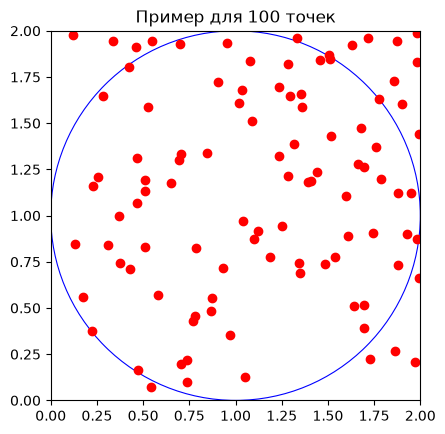

In [3]:
fig, axes = plt.subplots()

axes.set_xlim(0, 2)
axes.set_ylim(0, 2)
axes.set_aspect(1)

axes.add_artist(plt.Circle((1, 1), radius=1, fill=False, lw=0.8, color="b"))

X = 2*np.random.rand(100)
Y = 2*np.random.rand(100)
axes.scatter(X, Y, color="r")

plt.title('Пример для 100 точек')
plt.show()


Теперь сделаем это всё в виде цикла и выведем результаты

In [4]:
def approx_pi(N0, N1, step):
  points_count, approx = [], []

  for N in range(N0, N1+step, step):
    points = np.random.rand(N, 2)
    n = np.sum(points[:, 0]**2 + points[:, 1]**2 <= 1)  # сколько точек в окружности
    points_count.append(N)
    approx.append(4*n/N)

  return points_count, approx


In [5]:
N0 = 1000
N1 = 50000
step = 100

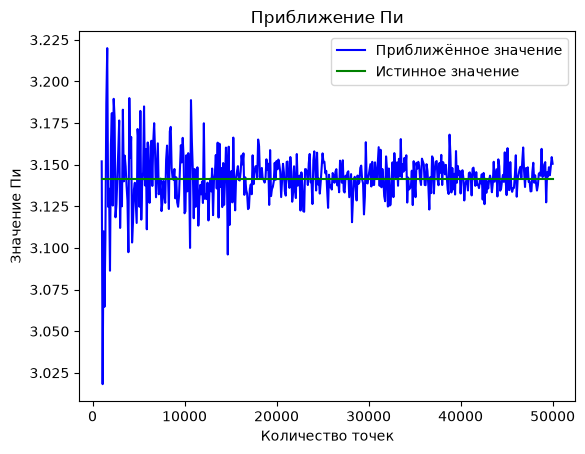

In [6]:
fig, axes = plt.subplots()

X, Y = approx_pi(N0, N1, step)

axes.plot(X, Y, color="b", label="Приближённое значение")
axes.plot((N0, N1), (np.pi, np.pi), color="g", label="Истинное значение")

plt.xlabel("Количество точек")
plt.ylabel("Значение Пи")
plt.legend()
plt.title('Приближение Пи')
plt.show()

## Задание 3

### Условие

Студент, в распоряжении которого есть T=10 часов времени, готовится к экзамену, на котором будет представлено N=10 различных билетов, вероятность выпадения каждого из которых одинакова. Он решает из N билетов попытаться выучить n (0 ⩽ n ⩽ N), при этом затратив на изучение каждого билета равное количество времени, а именно T/n. Функция обучаемости F(t) возвращает вероятность выучить билет, потратив на его изучение t часов (t ⩾ 0, t ∈ R), является строго монотонно возрастающей и удовлетворяет условиям F(0)=0, F(+∞)=1, 0 ⩽ F(t) < 1. Подобрать (придумать) функцию F(t), удовлетворяющую условиям F(1)=0.33, F(10)=0.95, и подобрать на её основе оптимальное значение n, с точки зрения максимизации вероятности успешной сдачи экзамена.

### Решение

Каким образом подбиралась функция F(t) показано на фотографиях задания 3 в папке ProbT_Pilipenko_Photos, ссылка была скинута вместе с ссылкой на этот файл. Здесь же я покажу, как подбирал оптимальное n

In [7]:
def F(t):
  _first = np.log(0.05) / np.log(0.67)
  _second = np.log(_first) / np.log(10)
  _third = t ** _second
  _fourth = 0.67 ** _third

  return 1 - _fourth

In [8]:
N = 10
T = 10

max_n = 0
max_P = 0

for n in range(1, N+1):
  P = n/N * F(T/n)

  if P >= max_P:
    max_P = P
    max_n = n

print("Оптимальное n =", max_n)

Оптимальное n = 10


## Задание 4

### Условие

 Реализовать на языке программирования Python функцию, которая будет численно находить значение функции Лапласа с заданным значением точности (под точностью можно подразумевать отличие найденного значения от табличного).

### Решение

In [9]:
def laplace(x):  # подынтегральная функция
  return np.exp(-0.5 * x**2) / np.sqrt(2*np.pi)

Решаем через формулу Симпсона (т.к. у неё хорошая точность)

N - количество разбиений отрезка [a, b]

In [10]:
def simpson_method(f, a, b, n):
  h = (b - a)/n  # шаг
  integ = f(a) + f(b)  # изначальное значение интеграла

  for i in range(1, n):  # начинаем с 1, т.к. 0 - это точка a
    integ += f(a + i*h) * 2**(i % 2 + 1)  # при чёт 2*f(x), при неч 4*f(x)

  return integ * h/3  # в конце умножаем на h/3

Погрешность этого метода оценивается как:

$$
E ≤ \frac{b-a}{2880} h^4 max_{x∈[a,b]}|f^{(4)}(x)|
$$

Через desmos я посмотрел значение 4 производной и получилось, что её максимум равен 1.19683 в точке 0. Можно округлить и тогда максимальное значение равно 1.2

Т.к. $h=\frac{b-a}{n}$ то:

$$
E ≤ 1.2\frac{(b-a)^5}{2880n^4}
$$

и следовательно для заданной погрешности количество разбиений определяется как

$$
n = \sqrt[4]{1.2\frac{(b-a)^5}{2880E}}
$$

Для сравнения я взял значения из [этой таблицы](https://studfile.net/html/35/35fb/35fb011eb70105eb6523532ac715d5a153f736c18faad97da973e02d6d6ca913/htmlconvd-YU1MCs_html_19ace8a948351913.jpg)

В таблице значения считаются до 4 знака после запятой

Т.к. погрешность считается как половина последнего разряда, то для точности в 4 знака после запятой, значение ошибки должно быть не больше, чем 5*10^-5 (я взял просто 10^-5)

In [11]:
a, b = 0, 2.5
precision = 4  # до скольки знаков после запятой считать

In [12]:
error = 10**-(precision+1)
n = int(np.ceil((1.2*(b-a)**5/(2880*error))**(1/4)))

In [13]:
table_val = 0.4938
my_val = np.round(simpson_method(laplace, a, b, n), precision)

print("Табличное значение:", table_val)
print("Моё значение:", my_val)

Табличное значение: 0.4938
Моё значение: 0.4938


## Задание 5

### Условие

1. Придумать свою случайную величину со значениями от 0 до 10 с помощью задания ее функции плотности вероятности (не использовать нормальное распределение). В блокноте Google Colab визуализировать ее
2. Визуализировать в Google Colab ее функц распределения
3. Найти чему равна вероятность того, что эта случайная величина будет принимать значения от 2 до 4

### Решение

$$
X ∈ (0, 10)
$$

Возьмём такую плотность распределения:

$$
f_X(u) = \frac{e-1}{10+u(e-1)}, u ∈ (0, 10)
$$

Функция распределния равна:

$$
F_X(t) = \int^{t}_{-\infty}{\frac{e-1}{10+u(e-1)}du}
$$

$$
F_X(t) = \int^{t}_{0}{\frac{e-1}{10+u(e-1)}du}
$$

$$
F_X(t) = {ln(10+u(e-1))|}_0^t
$$

$$
F_X(t) = ln(10+t(e-1)) - ln10
$$

Не совсем понял, что значит "визуализировать её" - имеется ввиду плотность или случайную величину? Сделал и то, и то

Для генерации случайной величины X_0, сначала найдём следующее:

$$
F_X(X_0) = a_0
$$

где $a_0 ∈ U(0, 1)$, т.е. $a_0$ распределяется равномерно

Тогда:

$$
X_0 = F_X^{-1}(a_0)
$$

И в нашем случае это равно:

$$
X_0 = 10\frac{e^{a_0}-1}{e-1}
$$

In [14]:
def pdf(x):
  return (np.exp(1) - 1) / (10 + x * (np.exp(1) - 1))

In [15]:
def cdf(x):
  return np.log(10 + x*(np.exp(1) - 1)) - np.log(10)

In [16]:
def generate_X(n):
  a = np.random.uniform(0.0, 1.0, n)
  return 10 * (np.exp(a) - 1) / (np.exp(1) - 1)

In [17]:
n = 10000

In [18]:
X = generate_X(n)

fig = go.Figure()

fig.add_trace(go.Histogram(x=X, histnorm="probability density", xbins={"start":0.0, "end":10.0}, name="Сгенерированные значения"))

X1 = np.linspace(0, 10, n)

fig.add_trace(go.Scatter(x=X1, y=pdf(X1), mode="lines", name="Теоретическая плотность"))

fig.update_layout(title="Генерация случайной величины X", xaxis_title="X", yaxis_title="Плотность", bargap=0.01)

fig.show()

In [19]:
fig = go.Figure()

X1 = np.linspace(0, 10, n)

fig.add_trace(go.Scatter(x=X1, y=cdf(X1), mode="lines"))

fig.update_layout(title="Функция распределения X", xaxis_title="X", yaxis_title="Распределение")

fig.show()

In [20]:
a, b = 2, 4
print(f"Вероятность, что случайная величина принимает значение от {a} до {b} равна {cdf(b)-cdf(a)}")

Вероятность, что случайная величина принимает значение от 2 до 4 равна 0.22774263449123788


## Задание 6

### Условие

Полагая, что рост мужчин определенной возрастной группы есть нормально распределенная случайная величинах X с параметрами а = 173 и σ2 = 36. Построить графики плотности распределения вероятности и функции распределения вероятности величины X и написать их аналитический вид. Определить доли костюмов 4-го роста (176— 182 см) и 3-го роста (170—176 см), которые нужно предусмотреть в общем объеме производства для данной возрастной группы.

### Решение

Аналитически плотность нормального распределения выглядит так:

$$
f(x) = \frac{1}{\sqrt{2\pi}σ}e^{-\frac{(x-a)^2}{2σ^2}}
$$

Функция распределения вероятности выглядит следующим образом:

$$
Φ(x) = \frac{1}{\sqrt{2\pi}σ}\int_{-\infty}^x{e^{-\frac{(t-a)^2}{2σ^2}}dt}
$$

Для случая $a=173$ и $σ^2=36$ формулы будут соответственно такими:

$$
f(x) = \frac{1}{6\sqrt{2\pi}}e^{-\frac{(x-173)^2}{72}}
$$

$$
Φ(x) = \frac{1}{6\sqrt{2\pi}}\int_{-\infty}^x{e^{-\frac{(t-173)^2}{72}}dt}
$$

In [21]:
a = 173
s = 6
n = 1000

In [22]:
X = np.linspace(a-s**2, a+s**2, n)

In [23]:
fig = go.Figure()

fig.add_trace(go.Scatter(x=X, y=norm.pdf(X, a, s), mode="lines"))

fig.update_layout(title="Функция плотности", xaxis_title="x", yaxis_title="y")

fig.show()

In [24]:
fig = go.Figure()

fig.add_trace(go.Scatter(x=X, y=norm.cdf(X, a, s), mode="lines"))

fig.update_layout(title="Функция распределения", xaxis_title="x", yaxis_title="y")

fig.show()

In [25]:
x1, x2 = 176, 182
y1, y2 = 170, 176
print(f"Доля костюмов размера {x1}-{x2} см равна {norm.cdf(x2, a, s)-norm.cdf(x1, a, s)}")
print(f"Доля костюмов размера {y1}-{y2} см равна {norm.cdf(y2, a, s)-norm.cdf(y1, a, s)}")

Доля костюмов размера 176-182 см равна 0.2417303374571288
Доля костюмов размера 170-176 см равна 0.38292492254802624
